# COMP 3800 Project 2

Mason Coleman

Fall 2026

### 1. Dataset Description and Prediction Goal

**Dataset**: Smartphone Usage and Addiction Analysis
- Shape: 7500 rows x 16 columns
- Each row is a record of smartphone usage
- Features include social media usage, gaming activity, sleep patterns, stress levels, and productivity impact
- Target Variable: addicted_label (0 = not addicted, 1 = addicted)
- Link: https://www.kaggle.com/datasets/jayjoshi37/smartphone-usage-and-addiction-prediction

**Classification Problem**: Implement binary classification with a K-Nearest neighbor algorithm.

**Prediction Goal**: Determine whether or not a subject is addicted to a smartphone device based on their behavior and digital activity.

#### Getting Familiar With The Data

In [1]:
# Import necessary modules and libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Create dataframe from data file and read the first 10 rows
df = pd.read_csv("Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")
df.head(10)

,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1
5,TXN00006,U00006,26,Male,9.32,4.26,0.29,3.99,6.90,82,56,10.98,Medium,Yes,Severe,1
6,TXN00007,U00007,25,Male,10.40,4.93,1.60,0.86,8.61,165,95,11.43,Medium,No,Severe,1
7,TXN00008,U00008,26,Male,4.26,4.60,2.16,4.61,6.43,169,117,5.66,Low,No,Moderate,1
8,TXN00009,U00009,21,Other,4.38,1.38,2.72,3.78,6.23,172,134,6.20,High,Yes,NaN,0
9,TXN00010,U00010,35,Other,9.76,4.73,1.36,2.11,5.21,20,82,12.69,Low,Yes,Severe,1


### 2. Data Cleaning

In [2]:
# Drop unwanted features
df = df.drop(columns=['transaction_id', 'user_id', 'addiction_level', 'gender', 'stress_level', 'academic_work_impact', 'addiction_level'])

# Rename target variable
df = df.rename(columns={"addicted_label": "target"})

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      7500 non-null   int64  
 1   daily_screen_time_hours  7500 non-null   float64
 2   social_media_hours       7500 non-null   float64
 3   gaming_hours             7500 non-null   float64
 4   work_study_hours         7500 non-null   float64
 5   sleep_hours              7500 non-null   float64
 6   notifications_per_day    7500 non-null   int64  
 7   app_opens_per_day        7500 non-null   int64  
 8   weekend_screen_time      7500 non-null   float64
 9   target                   7500 non-null   int64  
dtypes: float64(6), int64(4)
memory usage: 586.1 KB


In [3]:
# Remove any duplicates
df = df.drop_duplicates(keep='first')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      7500 non-null   int64  
 1   daily_screen_time_hours  7500 non-null   float64
 2   social_media_hours       7500 non-null   float64
 3   gaming_hours             7500 non-null   float64
 4   work_study_hours         7500 non-null   float64
 5   sleep_hours              7500 non-null   float64
 6   notifications_per_day    7500 non-null   int64  
 7   app_opens_per_day        7500 non-null   int64  
 8   weekend_screen_time      7500 non-null   float64
 9   target                   7500 non-null   int64  
dtypes: float64(6), int64(4)
memory usage: 586.1 KB


In [4]:
# Check target for inconsistent inputs
df['target'].value_counts(dropna=False)

target
1    5308
0    2192
Name: count, dtype: int64

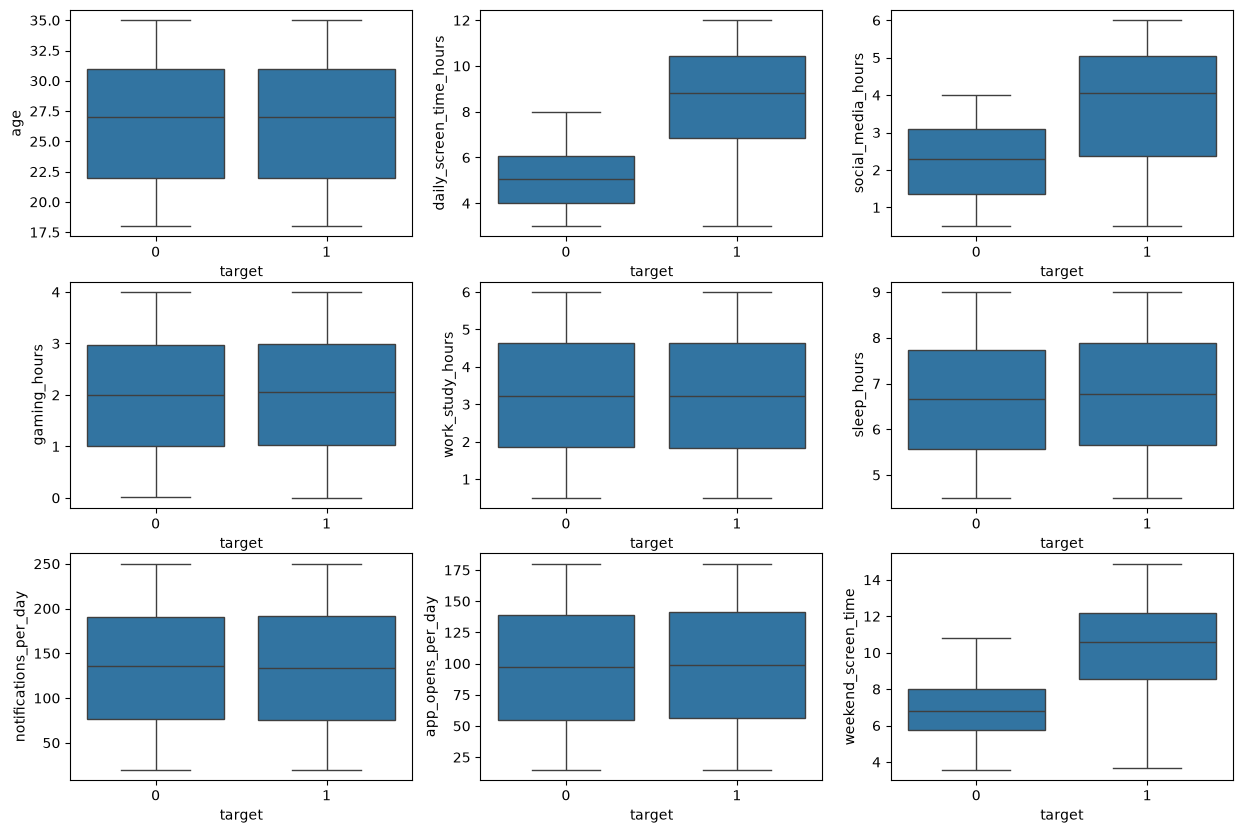

In [5]:
# Check for numeric variable outliers
num_columns = [
    'age', 
    'daily_screen_time_hours',
    'social_media_hours', 
    'gaming_hours', 
    'work_study_hours', 
    'sleep_hours', 
    'notifications_per_day', 
    'app_opens_per_day', 
    'weekend_screen_time'
    ]
fig=plt.figure(figsize=(15, 10))
for i in range(len(num_columns)):
    column=num_columns[i]
    sub=fig.add_subplot(3,3,i+1)
    sns.boxplot(x='target',y=column, data=df)

These boxplots can also help one see which features have an affect on the target. Graphs where the plots are widely different hint that the feature does affect the target.

Ex: daily_screen_time_hours, social_media_hours, weekend_screen_time

### 3. Feature Engineering

In [6]:
# ANOVA Test for Selecting Numerical Features

x = df.loc[:, num_columns]
y = df.loc[:, 'target']
fs = SelectKBest(score_func=f_classif, k='all')

# Train the model
bestFeatures = fs.fit(x, y)    

# Display the results
np.set_printoptions(suppress = True)
print(x.columns)
print()
print(f"F-Scores: {bestFeatures.scores_}")  
print()   
print(f"P-values: {bestFeatures.pvalues_}")

Index(['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours',
       'work_study_hours', 'sleep_hours', 'notifications_per_day',
       'app_opens_per_day', 'weekend_screen_time'],
      dtype='str')

F-Scores: [   0.13354596 3744.36288373 1553.16170063    0.53990014    0.00912934
    9.45896361    0.00326742    0.91420642 3345.06889702]

P-values: [0.71479374 0.         0.         0.46249709 0.92388244 0.00210876
 0.9544182  0.33903161 0.        ]


The ANOVA test helps determine which features should be used in building the prediction model by analyzing variance between the classes of the target. Features with p-values less than 0.05 are kept because they have a significant affect on the target. Relevant feautures also have greater f-scores. According to the test results, daily_screen_time_hours, social_media_hours, sleep_hours, and weekend_screen_time are the most relevant numerical features.

In [7]:
# Check for highly correlated features
x.corr()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time
age,1.000000,0.012767,0.000342,-0.026107,-0.017147,-0.007462,0.000387,-0.002276,0.015286
daily_screen_time_hours,0.012767,1.000000,0.010321,0.001140,0.003108,0.019343,0.000811,0.024448,0.964295
social_media_hours,0.000342,0.010321,1.000000,-0.000902,-0.002580,0.005947,-0.008593,-0.000371,0.011404
gaming_hours,-0.026107,0.001140,-0.000902,1.000000,0.004384,-0.002874,0.015563,-0.009917,-0.006282
work_study_hours,-0.017147,0.003108,-0.002580,0.004384,1.000000,-0.027150,-0.017518,-0.021676,0.004667
sleep_hours,-0.007462,0.019343,0.005947,-0.002874,-0.027150,1.000000,0.016273,0.005692,0.018933
notifications_per_day,0.000387,0.000811,-0.008593,0.015563,-0.017518,0.016273,1.000000,0.004598,-0.002199
app_opens_per_day,-0.002276,0.024448,-0.000371,-0.009917,-0.021676,0.005692,0.004598,1.000000,0.021069
weekend_screen_time,0.015286,0.964295,0.011404,-0.006282,0.004667,0.018933,-0.002199,0.021069,1.000000


The features daily_screen_time_hours and weekend_screen_time are highly correlated (with a correlation coefficient of 0.964295), and the classification model will lose effectiveness when independent variables are highly correlated. weekend_screen_time shall be removed because daily_screen_time_hours is the broader feature and accounts for weekend_screen_time.

In [8]:
# Feature Scaling

x_final = df.loc[:, ['daily_screen_time_hours', 'social_media_hours', 'sleep_hours']]
normalized_x= MinMaxScaler()    
x_scaled= normalized_x.fit_transform(x_final)

Feature scaling is vital for ensuring each feature has an equal effect and is on the same scale. K-Nearest Neighbor (KNN) algorithms depend on Euclidean Distance to classify unlabeled data, making normalization of data especially necessary.

### 4. Building the Prediction Model

In [9]:
# Create a list to store k-values
k_values = []

# Add K-values that are not multiples of 2 to list
for i in range(1, 26):
    if i % 2 != 0: 
        k_values.append(i)
print(k_values)

[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]


For this dataset, k should not be an even number because the target variable is binary in nature (not addicted = 0, addicted = 1), and ties can ensue between the classes, making it impossible to classify unlabeled data.

In [10]:
# Create a list to store the accuracy scores
k_accuracy_scores = []

# Build a KNN classifier for each k-value.
for k in k_values: 
    knn = KNeighborsClassifier(n_neighbors=k)
    # Get the cross-validation score for the classifier and store the average in the accuracy score list
    cv_scores = cross_val_score(knn, x_scaled, y, cv=10, scoring='f1')
    k_accuracy_scores.append(cv_scores.mean())

# Use a DataFrame to save k-values vs. each accuracy score. 
df_k_scores = pd.DataFrame(data = np.c_[k_values, k_accuracy_scores], columns = ['k', 'F1 Score']) 

df_k_scores

,k,F1 Score
0,1.0,0.946220
1,3.0,0.947073
2,5.0,0.947103
3,7.0,0.948098
4,9.0,0.947594
5,11.0,0.948311
6,13.0,0.949513
7,15.0,0.949287
8,17.0,0.950468
9,19.0,0.949669


For KNN classification models, cross vaidation is used to validate results because the technique ensures each data point is used for training and testing. This in turn produces stable, accurate results.

With a train-test split, accuracy varies with the data points being used for training and testing (random state). Altering the random state will yield an altered accuracy score. Consequently, it would be difficult to determine the accuracy of the KNN model.

F1 score is used to evaluate the model due to the unbalanced data (5308 cases of addiction, and 2192 cases of no addiction), which could make the accuracy score misleading.

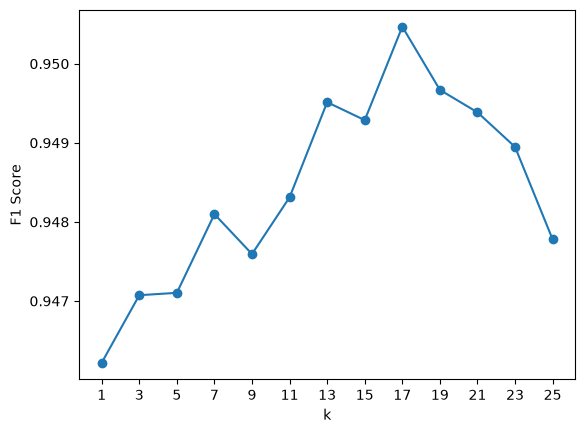

In [11]:
# Graphical representation of k-values and scores

plt.plot(k_values, k_accuracy_scores, marker='o')
plt.xlabel("k")
plt.xticks(k_values)
plt.ylabel("F1 Score")
plt.show()

The optimal k value is 17 with an F1 score of 95.05% making this a good model to use.